In [1]:
import xarray as xr
import numpy as np
import pandas as pd
from scipy.interpolate import griddata
import warnings
import matplotlib.pyplot as plt

In [2]:
try:
    dt = xr.open_mfdataset("./data/ice_conc_nh*.nc",
                           combine = 'by_coords',
                           chunks ={'time':'auto', 'xc':'auto', 'yc':'auto'})
    print("Dataset loaded successfully.")
    print("\nDataset Information:")
    print(dt)
except FileNotFoundError:
    print("Dataset files not found. Please check the file path and ensure the files exist.")
    dt = None

Dataset loaded successfully.

Dataset Information:
<xarray.Dataset> Size: 231MB
Dimensions:                         (time: 28, nv: 2, yc: 432, xc: 432)
Coordinates:
  * time                            (time) datetime64[ns] 224B 2002-06-01T12:...
  * xc                              (xc) float64 3kB -5.388e+03 ... 5.388e+03
  * yc                              (yc) float64 3kB 5.388e+03 ... -5.388e+03
    lat                             (yc, xc) float32 746kB dask.array<chunksize=(432, 432), meta=np.ndarray>
    lon                             (yc, xc) float32 746kB dask.array<chunksize=(432, 432), meta=np.ndarray>
Dimensions without coordinates: nv
Data variables:
    Lambert_Azimuthal_Grid          (time) int32 112B -2147483647 ... -214748...
    time_bnds                       (time, nv) datetime64[ns] 448B dask.array<chunksize=(1, 2), meta=np.ndarray>
    ice_conc                        (time, yc, xc) float64 42MB dask.array<chunksize=(1, 432, 432), meta=np.ndarray>
    raw_ice_conc_v

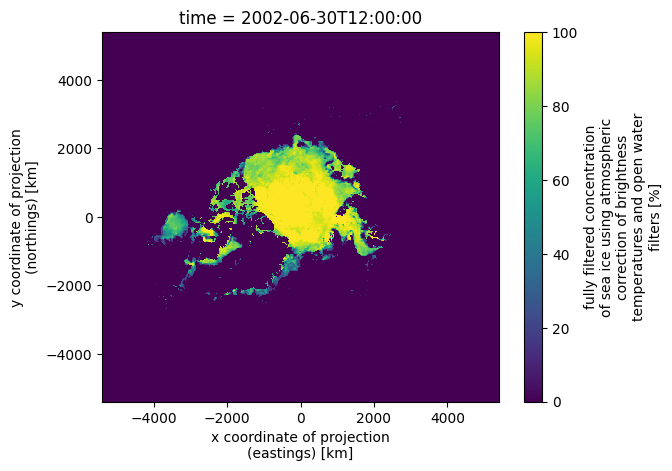

In [14]:
dt['ice_conc'].isel(time=27).plot(cmap='viridis')

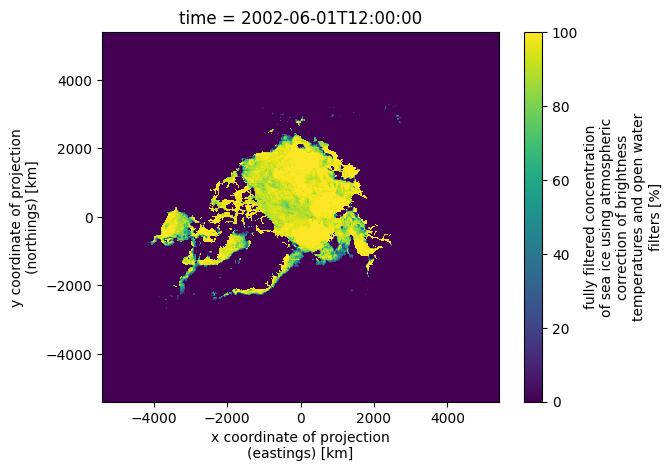

In [15]:
dt['ice_conc'].isel(time=0).plot(cmap='viridis')

In [12]:
dt['ice_conc'].isel(time=0).to_numpy()

array([[ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan]], shape=(432, 432))

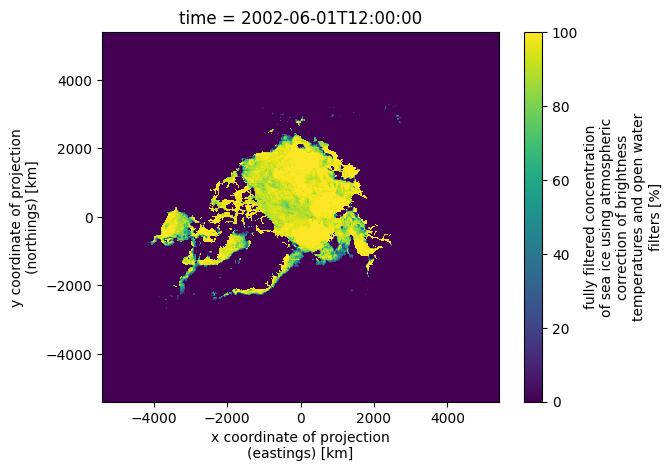

In [13]:
#interpolate nan to 0 in dt
dt['ice_conc'] = dt['ice_conc'].fillna(0)

dt['ice_conc'].isel(time=0).plot(cmap='viridis')

In [16]:
dt['ice_conc']

<xarray.DataArray 'ice_conc' (time: 28, yc: 432, xc: 432)> Size: 42MB
dask.array<where, shape=(28, 432, 432), dtype=float64, chunksize=(1, 432, 432), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 224B 2002-06-01T12:00:00 ... 2002-06-30T12...
  * xc       (xc) float64 3kB -5.388e+03 -5.362e+03 ... 5.362e+03 5.388e+03
  * yc       (yc) float64 3kB 5.388e+03 5.362e+03 ... -5.362e+03 -5.388e+03
    lat      (yc, xc) float32 746kB dask.array<chunksize=(432, 432), meta=np.ndarray>
    lon      (yc, xc) float32 746kB dask.array<chunksize=(432, 432), meta=np.ndarray>
Attributes:
    long_name:            fully filtered concentration of sea ice using atmos...
    standard_name:        sea_ice_area_fraction
    units:                %
    valid_min:            0
    valid_max:            10000
    grid_mapping:         Lambert_Azimuthal_Grid
    ancillary_variables:  total_standard_uncertainty status_flag
    comment:              this field is the primary sea ice concentration est...

In [2]:
import torch.nn as nn
import torch

In [3]:
class ConvLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size, kernel_size, bias):
        """
        input_size: channels of input tensor
        hidden_size: channels of hidden state
        kernel_size: size of the convolutional kernel
        bias: whether to use bias in the convolutional layer
        """
        super(ConvLSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.kernel_size = kernel_size
        self.bias = bias
        self.padding = kernel_size[0] // 2, kernel_size[1] // 2

        self.conv = nn.Conv2d(in_channels=self.input_size + self.hidden_size,
                              out_channels=4 * self.hidden_size,
                              kernel_size=self.kernel_size,
                              padding=self.padding,
                              bias=self.bias)

        self.Wci = nn.Conv2d(in_channels=self.hidden_size, out_channels=self.hidden_size, kernel_size=1, bias=self.bias)
        self.Wcf = nn.Conv2d(in_channels=self.hidden_size, out_channels=self.hidden_size, kernel_size=1, bias=self.bias)
        self.Wco = nn.Conv2d(in_channels=self.hidden_size, out_channels=self.hidden_size, kernel_size=1, bias=self.bias)

        
    def forward(self, x, curr_state):
        h_cur, c_cur = curr_state
        combined = torch.cat([x, h_cur], dim=1)
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv,
                                             split_size_or_sections=self.hidden_size,
                                             dim=1)
        i = torch.sigmoid(cc_i + self.Wci(c_cur))
        f = torch.sigmoid(cc_f + self.Wcf(c_cur))
        g = torch.tanh(cc_g)

        c_next = f * c_cur + i * g
        
        o = torch.sigmoid(cc_o + self.Wco(c_next))

        h_next = o * torch.tanh(c_next)

        return h_next, c_next



In [4]:
class ConvLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, kernel_size, num_layers, bias=True, return_sequences=False):
        super(ConvLSTM, self).__init__()
        self.input_size = input_size
        self.hidden_size = self._multilayer_support(hidden_size, num_layers)
        self.kernel_size = self._multilayer_support(kernel_size, num_layers)
        self.num_layers = num_layers
        self.bias = bias
        self.return_sequences = return_sequences
        cell_list = []
        
        for i in range(0, self.num_layers):
            curr_input_size = self.input_size if i == 0 else self.hidden_size[i-1]
            cell_list.append(ConvLSTMCell(input_size=curr_input_size,
                                          hidden_size=self.hidden_size[i],
                                          kernel_size=self.kernel_size[i],
                                          bias=self.bias))
            
        self.cell_list = nn.ModuleList(cell_list)

        self.output_projection = nn.Conv2d(in_channels=self.hidden_size[-1],
                                           out_channels=self.input_size,
                                           kernel_size=1,
                                           bias=self.bias)
        
        self.output_activation = nn.Sigmoid()

    def forward(self, x, hidden_state=None):
        b, seq_len, _, h, w = x.size()

        if hidden_state is None:
            hidden_state = self._init_hidden(b, (h, w), x.device)
        else:
            pass

        last_layer_output_sequence = []

        for t in range(seq_len):
            x_t = x[:,t,:,:,:]

            next_hidden_t = []

            #unrolling

            for idx in range(self.num_layers):
                cell = self.cell_list[idx]

                h_cur, c_cur = hidden_state[idx]
                h_next, c_next = cell(x=x_t, curr_state=[h_cur, c_cur])

                next_hidden_t.append((h_next, c_next))
                
                x_t = h_next
            
            hidden_state = next_hidden_t
            last_layer_output_sequence.append(x_t)

        last_layer_output_sequence = torch.stack(last_layer_output_sequence, dim = 0)
        #now seq_len is the first dimension
        last_layer_output_sequence = last_layer_output_sequence.permute(1, 0, 2, 3, 4)

        if self.return_sequences:
            projected_output = self.output_projection(last_layer_output_sequence.view(-1, self.hidden_size[-1], h, w))
            projected_output = projected_output.view(b, seq_len, self.input_size, h, w)
        else:
            projected_output = self.output_projection(last_layer_output_sequence[:,-1,:,:,:])
        
        
        final_prediction = self.output_activation(projected_output)

        return final_prediction


    def _init_hidden(self, batch_size, image_size, device):
        H, W = image_size
        init_states = []
        for i in range(self.num_layers):
            init_states.append((torch.zeros(batch_size, self.hidden_size[i], H, W, device=device),
                                torch.zeros(batch_size, self.hidden_size[i], H, W, device=device)))
        return init_states

    @staticmethod
    def _multilayer_support(x, num_layers):
        if (not isinstance(x, list)):
            x = [x] * num_layers
        return x
        

In [8]:
# testing

batch_size = 4
sequence_length = 5
input_channels = 1
height = 64
width = 64
num_layers = 2

hidden_channels = [16, 32]  # Example hidden channels for each layer
kernel_size = [(3, 3), (3, 3)]  # Example kernel sizes for each layer
bias = True  # Whether to use bias in the convolutional layers

dummy_input = torch.randn(batch_size, sequence_length, input_channels, height, width)
print("Dummy input shape:", dummy_input.shape)

Dummy input shape: torch.Size([4, 5, 1, 64, 64])


In [9]:
model_single_frame = ConvLSTM(
        input_size=input_channels,
        hidden_size=hidden_channels,
        kernel_size=kernel_size,
        num_layers=num_layers,
        return_sequences=False # We want only the last prediction
    )


In [12]:
output = model_single_frame(dummy_input)

In [14]:
output.shape

torch.Size([4, 1, 64, 64])

(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

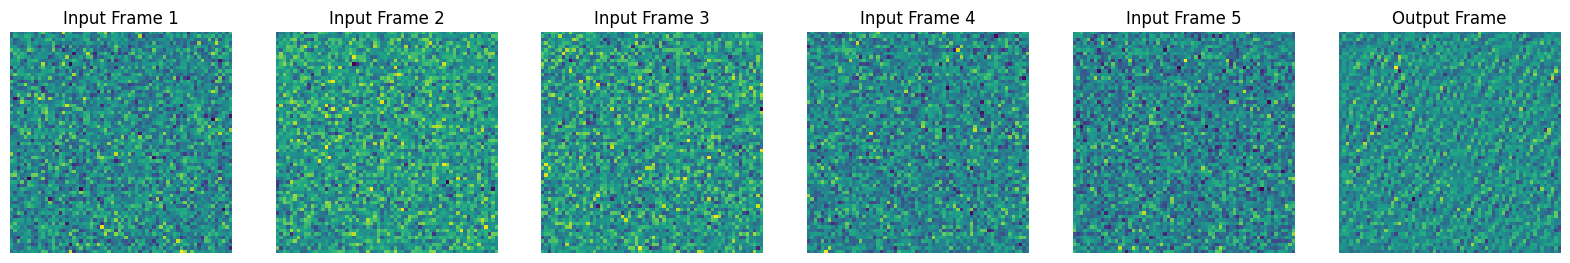

In [16]:
#visualize a heat map of 5 inputs and then the output
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(20, 5))
for i in range(sequence_length):
    axes[i].imshow(dummy_input[0, i, 0].numpy(), cmap='viridis')
    axes[i].set_title(f'Input Frame {i+1}')
    axes[i].axis('off')
axes[-1].imshow(output[0, 0].detach().numpy(), cmap='viridis')
axes[-1].set_title('Output Frame')
axes[-1].axis('off')

In [5]:
#create dummy input. square moving from left to right. to create 100 images
dummy_input = torch.zeros(100, 1, 64, 64)
for i in range(100):
    dummy_input[i, 0, :, :] = 1.0  # Create a white square
    dummy_input[i, 0, :, i % 64] = 0.0  # Move the square

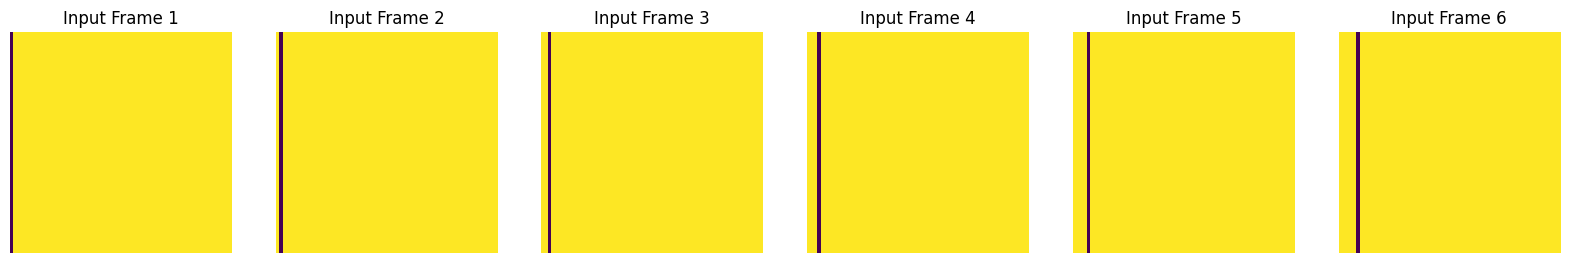

In [7]:
import matplotlib.pyplot as plt
# plot the dummy input
fig, axes = plt.subplots(1, 6, figsize=(20, 5))
for i in range(6):
    axes[i].imshow(dummy_input[i, 0].numpy(), cmap='viridis')
    axes[i].set_title(f'Input Frame {i+1}')
    axes[i].axis('off')

In [8]:
model = ConvLSTM(
    input_size=1,  # Number of input channels
    hidden_size=32,  # Hidden channels for each layer
    kernel_size=(3, 3),  # Kernel sizes for each layer
    num_layers=25,  # Number of layers
    return_sequences=False  # We want only the last prediction
)


(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

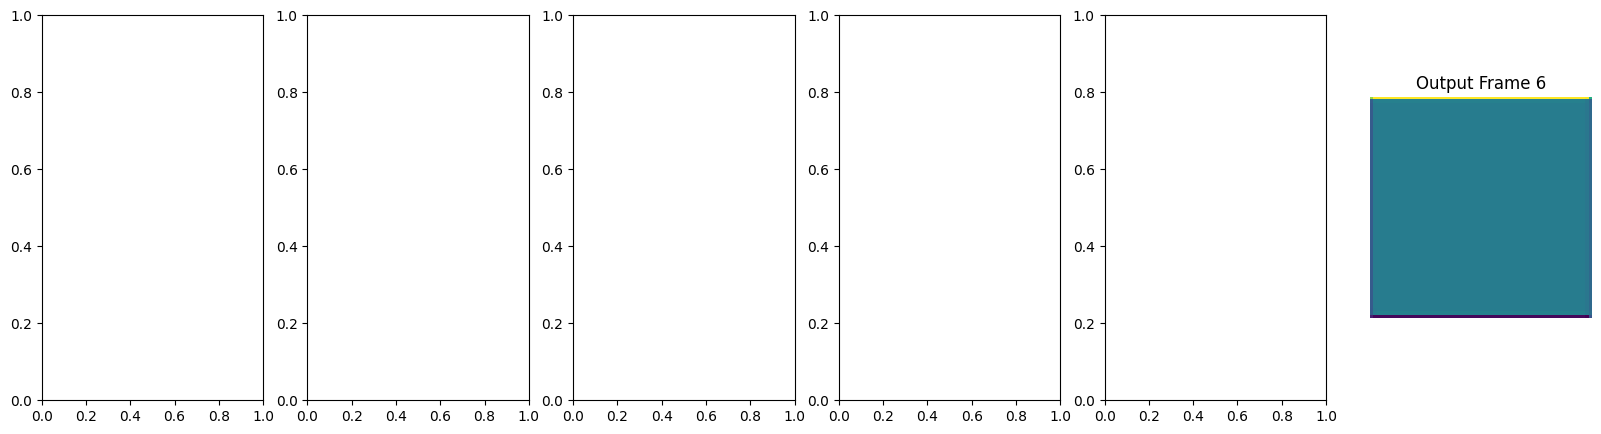

In [10]:
#print output
fig, axes = plt.subplots(1, 6, figsize=(20, 5))

axes[i].imshow(output[0, 0].detach().numpy(), cmap='viridis')
axes[i].set_title(f'Output Frame {i+1}')
axes[i].axis('off')

In [9]:
output =  model(dummy_input.unsqueeze(1))  # Add a batch dimension
output.shape

torch.Size([100, 1, 64, 64])

In [11]:
output

tensor([[[[0.4953, 0.4954, 0.4954,  ..., 0.4954, 0.4954, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          ...,
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4952, 0.4952,  ..., 0.4952, 0.4952, 0.4953]]],


        [[[0.4953, 0.4954, 0.4954,  ..., 0.4954, 0.4954, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          ...,
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4952, 0.4952,  ..., 0.4952, 0.4952, 0.4953]]],


        [[[0.4953, 0.4954, 0.4954,  ..., 0.4954, 0.4954, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..., 0.4953, 0.4953, 0.4953],
          [0.4953, 0.4953, 0.4953,  ..